Objetivo:

Ajustar (fine-tune) un modelo ResNet18 en un subconjunto personalizado (ej. 2 clases) de imágenes satelitales.

In [1]:
import torch
import torchvision
from torchvision import transforms, models, datasets
from torch import nn, optim
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import os

In [2]:
# Configuración de transformaciones para imágenes satelitales
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [3]:
# Descargar y cargar EuroSAT dataset (RGB)
train_dataset = datasets.EuroSAT(
    root='./data/eurosat',  # Directorio donde se guardarán los datos
    download=True,          # Descargar si no existe
    transform=transform
)

100%|██████████| 94.3M/94.3M [00:00<00:00, 160MB/s]


In [4]:
# Crear DataLoader
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4)

/usr/local/lib/python3.11/dist-packages/torch/utils/data/dataloader.py:624: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(


In [5]:
# Configurar dispositivo
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Usando dispositivo: {device}")

Usando dispositivo: cuda


In [6]:
# Cargar ResNet18 pre-entrenada
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 187MB/s]


In [7]:
# Congelar todos los parámetros excepto la capa final
for param in model.parameters():
    param.requires_grad = False

In [8]:
# Reemplazar la capa final (EuroSAT tiene 10 clases)
num_classes = 10
model.fc = nn.Sequential(
    nn.Linear(model.fc.in_features, 512),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(512, num_classes)
)
model = model.to(device)

In [9]:
# Configurar función de pérdida y optimizador
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

In [10]:
# Función para calcular precisión
def accuracy(outputs, labels):
    _, preds = torch.max(outputs, 1)
    return torch.tensor(torch.sum(preds == labels).item() / len(preds))

In [11]:
# Entrenamiento mejorado
num_epochs = 10
train_losses = []
train_accs = []

La siguiente celda consiste en entrenar al modelo, implica aproximadamente 10 minutos de tiempo de procesamiento si se cambia el "Entorno de Ejecución" a GPU.

In [12]:
for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0
    epoch_acc = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        acc = accuracy(outputs, labels)

        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        epoch_acc += acc

    # Calcular promedios
    epoch_loss /= len(train_loader)
    epoch_acc /= len(train_loader)

    train_losses.append(epoch_loss)
    train_accs.append(epoch_acc)

    print(f'Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.4f}, Accuracy: {epoch_acc:.4f}')

Epoch 1/10, Loss: 0.4538, Accuracy: 0.8478
Epoch 2/10, Loss: 0.3154, Accuracy: 0.8892
Epoch 3/10, Loss: 0.2789, Accuracy: 0.9016
Epoch 4/10, Loss: 0.2644, Accuracy: 0.9081
Epoch 5/10, Loss: 0.2423, Accuracy: 0.9152
Epoch 6/10, Loss: 0.2322, Accuracy: 0.9175
Epoch 7/10, Loss: 0.2207, Accuracy: 0.9222
Epoch 8/10, Loss: 0.2181, Accuracy: 0.9231
Epoch 9/10, Loss: 0.2077, Accuracy: 0.9268
Epoch 10/10, Loss: 0.2031, Accuracy: 0.9279


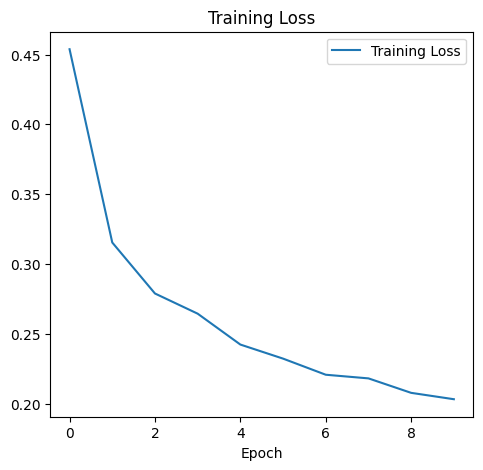

In [13]:
# Visualización de resultados
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Training Loss')
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.legend()

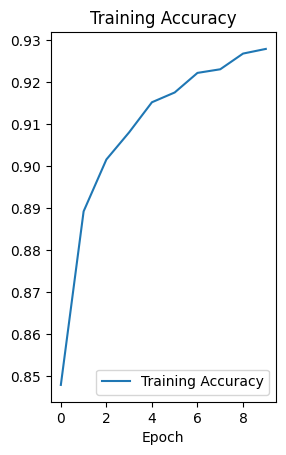

In [14]:
plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Training Accuracy')
plt.title('Training Accuracy')
plt.xlabel('Epoch')
plt.legend()

In [15]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

Solución esperada:

Precisión decente (80–90%) en pocas épocas con solo ajustar la capa final del modelo.